In [1]:
import numpy as np
from sklearn.datasets import load_iris 
from sklearn.linear_model import Perceptron 

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)

In [2]:
y_pred

array([ True, False])

In [3]:
y

0       True
1       True
2       True
3       True
4       True
       ...  
145    False
146    False
147    False
148    False
149    False
Name: target, Length: 150, dtype: bool

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)




In [5]:
rmse

0.5053326657968684

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

dummy = make_pipeline(
    StandardScaler(),
    DummyRegressor(strategy="mean")
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_valid)

dummy_rmse = root_mean_squared_error(y_valid, dummy_pred)

print("Baseline rmse : ", dummy_rmse)
print("Neural Network rmse : ", rmse)

Baseline rmse :  1.1476260241965577
Neural Network rmse :  0.5053326657968684


In [7]:
from sklearn.ensemble import RandomForestRegressor

rfr = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

rfr.fit(X_train, y_train)

rfr_pred = rfr.predict(X_valid)

rfr_rmse = root_mean_squared_error(y_valid, rfr_pred)

print("Random Forest rmse: ", rfr_rmse)

Random Forest rmse:  0.5073847566107056


In [8]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[5])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.4629100498862757


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.7857142857142857


In [10]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[10])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.4225771273642583


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.8214285714285714


In [12]:
import tensorflow as tf 

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist 
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

I0000 00:00:1794239881.359549    6161 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [13]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (55000, 28, 28) (55000,)
Validation: (5000, 28, 28) (5000,)
Testing: (10000, 28, 28) (10000,)


In [14]:
X_train, X_valid, X_test = (
    X_train / 255. ,
    X_valid / 255. ,
    X_test / 255. 
)

In [15]:
print(X_train.min())
print(X_train.max())
print(X_train.dtype)

0.0
1.0
float64


In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker","Bag", "Ankle boot"]

In [17]:
class_names[y_train[8]]

'Sandal'

In [18]:
class_names[y_train[4]]

'T-shirt/top'

In [19]:
tf.random.set_seed(42)

model = tf.keras.Sequential()

model.add(tf.keras.layers.Input(shape=[28, 28]))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(300,activation="relu"))

model.add(tf.keras.layers.Dense(100,activation="relu"))

model.add(tf.keras.layers.Dense(10,activation="softmax"))
 

W0000 00:00:1794239886.570825    6161 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

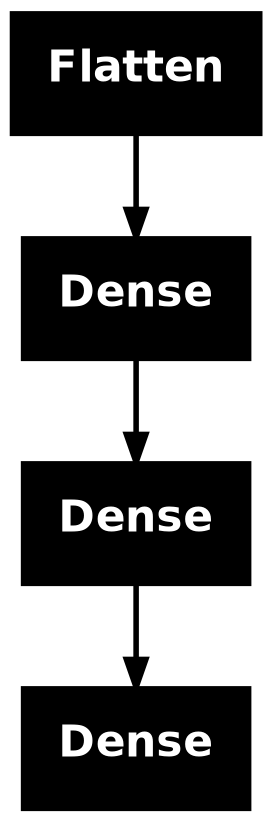

In [22]:
tf.keras.utils.plot_model(model)

In [23]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <Dense name=dense_4, built=True>,
 <Dense name=dense_5, built=True>]

In [24]:
hidden1 = model.layers[1]

In [25]:
hidden1

<Dense name=dense_3, built=True>

In [26]:
model.get_layer('dense_3') is hidden1

True

In [27]:
weights, biases = hidden1.get_weights()

In [28]:
weights

array([[ 0.0151935 , -0.07375788, -0.04918366, ..., -0.06393214,
        -0.00614503,  0.0636692 ],
       [-0.01864234, -0.04266059, -0.05170027, ..., -0.03217134,
        -0.03718727, -0.062948  ],
       [ 0.02234834, -0.07102572,  0.02441084, ...,  0.04154573,
         0.04461785,  0.05142777],
       ...,
       [ 0.02003291,  0.01698795,  0.01490267, ...,  0.02686996,
         0.00324601,  0.0372832 ],
       [-0.07274516, -0.01079801, -0.02408031, ...,  0.05135202,
         0.01018205, -0.05706942],
       [ 0.0008032 , -0.0185069 , -0.01500935, ..., -0.03858443,
        -0.0618624 ,  0.04152226]], shape=(784, 300), dtype=float32)

In [29]:
weights.shape


(784, 300)

In [30]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [31]:
biases.shape

(300,)

In [32]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

In [33]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30


W0000 00:00:1794239887.788175    6161 cpu_allocator_impl.cc:82] Allocation of 172480000 exceeds 10% of free system memory.


1674/1719 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7690 - loss: 0.7007

W0000 00:00:1794239890.813256    6161 cpu_allocator_impl.cc:82] Allocation of 15680000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.7701 - loss: 0.6957 - val_accuracy: 0.8312 - val_loss: 0.5034
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8329 - loss: 0.4809 - val_accuracy: 0.8408 - val_loss: 0.4534
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8475 - loss: 0.4374 - val_accuracy: 0.8474 - val_loss: 0.4308
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8565 - loss: 0.4108 - val_accuracy: 0.8504 - val_loss: 0.4170
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8627 - loss: 0.3912 - val_accuracy: 0.8552 - val_loss: 0.4038
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8680 - loss: 0.3753 - val_accuracy: 0.8566 - val_loss: 0.3956
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8726 - loss: 0.3622 - val_accuracy: 0.8592 - val_loss: 0.3867
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8757 - loss: 0.3508 - val_accurac

In [34]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1719}

In [35]:
history.epoch

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

In [36]:
history.history

{'accuracy': [0.7701091170310974,
  0.8328909277915955,
  0.8474909067153931,
  0.8564727306365967,
  0.862672746181488,
  0.8680182099342346,
  0.8726363778114319,
  0.8757272958755493,
  0.8788727521896362,
  0.8820727467536926,
  0.8850545287132263,
  0.8878545165061951,
  0.8897091150283813,
  0.8921818137168884,
  0.8935636281967163,
  0.8958545327186584,
  0.8981817960739136,
  0.9003454446792603,
  0.9023454785346985,
  0.9043999910354614,
  0.906145453453064,
  0.9076545238494873,
  0.9095818400382996,
  0.9111636281013489,
  0.9128909111022949,
  0.9143454432487488,
  0.9159091114997864,
  0.9172363877296448,
  0.9190545678138733,
  0.9204545617103577],
 'loss': [0.6957454681396484,
  0.48085817694664,
  0.43739262223243713,
  0.41079437732696533,
  0.39116182923316956,
  0.37532758712768555,
  0.3621704876422882,
  0.35082659125328064,
  0.34073981642723083,
  0.33174481987953186,
  0.3234056830406189,
  0.31576162576675415,
  0.3085452914237976,
  0.3017841577529907,
  0.295

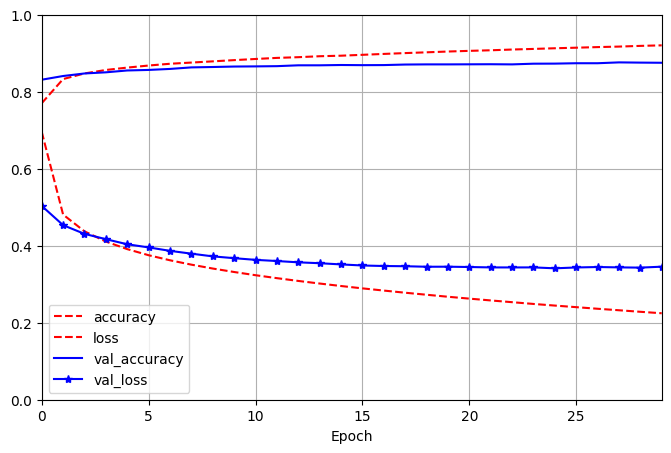

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(history.history).plot(
    figsize=(8,5), xlim=[0,29], ylim=[0, 1], xlabel="Epoch", style=["r--", "r--", "b-","b-*"])
plt.grid()
plt.show()


In [38]:
model.evaluate(X_test, y_test)

197/313 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - accuracy: 0.8698 - loss: 0.3734

W0000 00:00:1794239956.481320    6161 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 819us/step - accuracy: 0.8737 - loss: 0.3627


[0.36267343163490295, 0.8737000226974487]

In [39]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.06, 0.  , 0.01, 0.  , 0.94],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [40]:
y_test[:3]

array([9, 2, 1], dtype=uint8)

In [41]:
import numpy as np
y_pred = y_proba.argmax(axis=1)
y_pred

array([9, 2, 1])

In [49]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)

In [50]:
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["root_mean_squared_error"])
norm_layer.adapt(X_train)
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test , rmse_test = model.evaluate(X_test, y_test)

Epoch 1/20


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.8252 - root_mean_squared_error: 0.9084 - val_loss: 0.6047 - val_root_mean_squared_error: 0.7776
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3962 - root_mean_squared_error: 0.6294 - val_loss: 0.4397 - val_root_mean_squared_error: 0.6631
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3548 - root_mean_squared_error: 0.5957 - val_loss: 0.5650 - val_root_mean_squared_error: 0.7517
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3458 - root_mean_squared_error: 0.5881 - val_loss: 0.5744 - val_root_mean_squared_error: 0.7579
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3314 - root_mean_squared_error: 0.5757 - val_loss: 0.4759 - val_root_mean_squared_error: 0.6898
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3232 - root_mean_squared_error: 0.5685 - val_loss: 0.6974 - val_root_mean_squared_error: 0.8351
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3

In [51]:
X_new = X_test[:3]
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


array([[0.53652674],
       [1.19726   ],
       [5.100191  ]], dtype=float32)

In [52]:
X_new.shape

(3, 8)

In [53]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [62]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation="relu")
hidden_layer2 = tf.keras.layers.Dense(30, activation="relu")
concat_layer  = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])
model.compile(loss="mse", optimizer="adam", metrics=["root_mean_squared_error"])
normalization_layer.adapt(X_train)
model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.1127 - root_mean_squared_error: 1.0548 - val_loss: 0.7292 - val_root_mean_squared_error: 0.8539
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4273 - root_mean_squared_error: 0.6537 - val_loss: 0.3840 - val_root_mean_squared_error: 0.6197
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3769 - root_mean_squared_error: 0.6139 - val_loss: 0.3694 - val_root_mean_squared_error: 0.6078
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3574 - root_mean_squared_error: 0.5979 - val_loss: 0.3524 - val_root_mean_squared_error: 0.5936
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3472 - root_mean_squared_error: 0.5892 - val_loss: 0.5406 - val_root_mean_squared_error: 0.7353
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3380 - root_mean_squared_error: 0.5814 - val_loss: 0.6466 - val_root_mean_squared_error: 0.8041
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

In [64]:
X_new = X_test[:3]
X_new.shape

(3, 8)

In [65]:
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


array([[0.5482595],
       [1.35115  ],
       [4.445346 ]], dtype=float32)

In [66]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])